# Sonnendach-Potenzial in Winterthur: Datenanalyse und Prognose

**Forschungsfrage:** Wie hängen Dachfläche, Ausrichtung und Neigung mit dem
vom BFE geschätzten jährlichen Solarstromertrag zusammen, und wie gut lässt
sich dieser Ertrag für bisher ungesehene Gebäude vorhersagen?

Die Analyse nutzt die öffentliche geo.admin.ch-API für ein Gebiet von
500 x 500 m in der Winterthurer Altstadt (LV95/EPSG:2056). Der Zielwert ist
ein modellierter Potenzialwert der Solarkarte, keine Messung real erzeugten
Stroms und keine Aussage über installierte Anlagen.

Schritte: API-Datenerhebung, Datenbereinigung und Merkmalsbildung,
SQLite/SQL, explorative Datenanalyse, Geovisualisierung, Korrelationstest
mit p-Wert sowie Vergleich von linearer Regression und Random Forest.
Die Gruppenaufteilung erfolgt gebäudeweise, damit Dachflächen desselben
Gebäudes nicht gleichzeitig in Trainings- und Testdaten landen.

In [11]:
from __future__ import annotations

import json
import os
import time
from pathlib import Path

import folium
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from sqlalchemy import create_engine, text
from IPython.display import display
from pyproj import Transformer
from scipy.stats import spearmanr
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42
PAGE_SIZE = 200
MAX_OFFSET = 20_000
TIMEOUT_SECONDS = 60
API_URL = "https://api3.geo.admin.ch/rest/services/ech/MapServer/identify"
LAYER = "ch.bfe.solarenergie-eignung-daecher"
BBOX = (2696600, 1261600, 2697100, 1262100)

# Ausgaben bleiben im Projektordner, auch wenn VS Code das Workspace-Root nutzt.
CWD = Path.cwd().resolve()
PROJECT_DIR = (
    CWD
    if CWD.name == "projekt 2.0"
    else CWD / "projekt 2.0"
    if (CWD / "projekt 2.0").is_dir()
    else CWD
)
RAW_CSV = PROJECT_DIR / "solar_test_winterthur_altstadt_raw.csv"
CLEAN_CSV = PROJECT_DIR / "solar_test_winterthur_altstadt_clean.csv"
DATABASE = PROJECT_DIR / "sonnendach_winterthur.sqlite"
MAP_HTML = PROJECT_DIR / "sonnendach_winterthur_karte.html"

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)


def esri_geometry_to_geojson(geometry: dict | None) -> dict | None:
    """Wandelt ESRI-Ringgeometrie (LV95) in GeoJSON-Polygon (WGS84) um."""
    if not geometry or not geometry.get("rings"):
        return None
    transformer = Transformer.from_crs("EPSG:2056", "EPSG:4326", always_xy=True)
    rings = []
    for ring in geometry["rings"]:
        transformed_ring = []
        for x_coord, y_coord in ring:
            longitude, latitude = transformer.transform(x_coord, y_coord)
            transformed_ring.append([longitude, latitude])
        rings.append(transformed_ring)
    return {"type": "Polygon", "coordinates": rings}

## 1. Datenerhebung über die Web-API

Die geo.admin identify-Antwort kann bei `limit=200` eine zusätzliche
Sentinel-Zeile mit `featureId=-99` enthalten. Diese wird dokumentiert und in
der Bereinigung entfernt. Die API-Seiten werden über `offset` gelesen und
anhand der Feature-ID dedupliziert.

In [12]:
def abfrage(
    bbox: tuple[int, int, int, int], offset: int = 0, limit: int = PAGE_SIZE
) -> list[dict]:
    """Fragt eine Seite der geo.admin identify-API ab."""
    if not 1 <= limit <= PAGE_SIZE:
        raise ValueError(f"limit muss zwischen 1 und {PAGE_SIZE} liegen.")
    if offset < 0:
        raise ValueError("offset darf nicht negativ sein.")

    params = {
        "geometry": ",".join(str(value) for value in bbox),
        "geometryType": "esriGeometryEnvelope",
        "layers": f"all:{LAYER}",
        "tolerance": 0,
        "sr": 2056,
        "returnGeometry": "true",
        "limit": limit,
        "offset": offset,
    }
    response = requests.get(API_URL, params=params, timeout=TIMEOUT_SECONDS)
    response.raise_for_status()
    payload = response.json()
    results = payload.get("results") if isinstance(payload, dict) else None
    if not isinstance(results, list):
        raise ValueError("Die API-Antwort enthält keine gültige 'results'-Liste.")
    return results


api_results: list[dict] = []
seen_feature_ids: set[int] = set()
page_log: list[dict[str, int]] = []

for offset in range(0, MAX_OFFSET, PAGE_SIZE):
    page = abfrage(BBOX, offset=offset)
    new_results = []
    for result in page:
        feature_id = result.get("featureId")
        if feature_id is None or feature_id not in seen_feature_ids:
            new_results.append(result)
            if feature_id is not None:
                seen_feature_ids.add(feature_id)
    api_results.extend(new_results)
    page_log.append(
        {"offset": offset, "received": len(page), "new": len(new_results)}
    )
    print(
        f"offset {offset:>5}: {len(page):>3} API-Ergebnisse, "
        f"{len(new_results):>3} neu; total {len(api_results)}"
    )
    if len(page) < PAGE_SIZE:
        break
    time.sleep(0.1)
else:
    raise RuntimeError(f"Sicherheitsstopp bei offset={MAX_OFFSET}.")

page_log_df = pd.DataFrame(page_log)
print(f"\nAPI-Ergebnisse (inkl. Sentinel): {len(api_results)}")
print("Ergebnisse pro Seite:")
display(page_log_df)

offset     0: 201 API-Ergebnisse, 201 neu; total 201
offset   200: 200 API-Ergebnisse, 200 neu; total 401
offset   400: 200 API-Ergebnisse, 200 neu; total 601
offset   600: 200 API-Ergebnisse, 200 neu; total 801
offset   800: 200 API-Ergebnisse, 200 neu; total 1001
offset  1000: 200 API-Ergebnisse, 200 neu; total 1201
offset  1200: 112 API-Ergebnisse, 112 neu; total 1313

API-Ergebnisse (inkl. Sentinel): 1313
Ergebnisse pro Seite:


,offset,received,new
0,0,201,201
1,200,200,200
2,400,200,200
3,600,200,200
4,800,200,200
5,1000,200,200
6,1200,112,112


## 2. Rohdaten, Datenbereinigung und neue Merkmale

`featureId=-99` ist kein gültiges Dachmerkmal und wird entfernt. Doppelte
Feature-IDs werden eliminiert. Fehlende Gebäude-IDs bleiben für die Analyse
erhalten; beim gruppierten Split erhalten diese Dächer jeweils eine eigene
Ersatzgruppe. Fehlende Zielwerte oder unbrauchbare Eingangsmerkmale werden
nicht imputiert, sondern für die Modellierung ausgeschlossen.

`ausrichtung` ist ein Winkel. Sinus und Kosinus bilden die Zirkularität ab,
sodass z. B. Winkel nahe -180° und 180° nicht fälschlich weit auseinander
liegen.

In [13]:
raw_rows = []
for result in api_results:
    row = dict(result.get("attributes", {}))
    row["featureId"] = result.get("featureId")
    row["geometry_esri"] = json.dumps(
        result.get("geometry"), ensure_ascii=False, separators=(",", ":")
    )
    raw_rows.append(row)

df_raw = pd.DataFrame(raw_rows)
df_raw.to_csv(RAW_CSV, index=False)

df = df_raw.copy()
df["featureId"] = pd.to_numeric(df["featureId"], errors="coerce")
df = df.loc[df["featureId"].notna() & df["featureId"].ne(-99)].copy()
df = df.drop_duplicates(subset="featureId", keep="first")

numeric_columns = [
    "building_id",
    "gwr_egid",
    "klasse",
    "flaeche",
    "ausrichtung",
    "neigung",
    "stromertrag",
    "stromertrag_winterhalbjahr",
    "stromertrag_sommerhalbjahr",
    "gstrahlung",
    "mstrahlung",
    "waermeertrag",
    "finanzertrag",
]
for column in numeric_columns:
    if column in df:
        df[column] = pd.to_numeric(df[column], errors="coerce")

df["geometry_geojson"] = df["geometry_esri"].map(
    lambda value: json.dumps(
        esri_geometry_to_geojson(json.loads(value)),
        ensure_ascii=False,
        separators=(",", ":"),
    )
    if pd.notna(value) and value != "null"
    else None
)

# Die folgenden Felder werden für die beschreibende und modellierende
# Analyse verwendet. Ertragsbestandteile und gstrahlung werden bewusst nicht
# als Prädiktoren verwendet: sie sind aus dem Zielwert abgeleitet bzw. nahezu
# proportional dazu und würden Datenleckage erzeugen.
analysis_columns = [
    "featureId",
    "building_id",
    "gwr_egid",
    "klasse",
    "flaeche",
    "ausrichtung",
    "neigung",
    "stromertrag",
    "geometry_geojson",
]
df = df[[column for column in analysis_columns if column in df]].copy()
before_model_filter = len(df)
df = df.dropna(subset=["flaeche", "ausrichtung", "neigung", "stromertrag"])
df = df.loc[(df["flaeche"] > 0) & (df["stromertrag"] >= 0)].copy()

df["ausrichtung_sin"] = np.sin(np.deg2rad(df["ausrichtung"]))
df["ausrichtung_cos"] = np.cos(np.deg2rad(df["ausrichtung"]))
df["log_flaeche"] = np.log1p(df["flaeche"])
df["building_group"] = df["building_id"].astype("Int64").astype("string")
missing_building = df["building_group"].isna()
df.loc[missing_building, "building_group"] = (
    "roof-" + df.loc[missing_building, "featureId"].astype("Int64").astype("string")
)

print(f"Rohzeilen: {len(df_raw):,}")
print(f"Nach Entfernung ungültiger/duplizierter IDs: {before_model_filter:,}")
print(f"Analysefähige Dachflächen: {len(df):,}")
print(f"Verschiedene bekannte building_id: {df['building_id'].nunique():,}")
print(f"Fehlende building_id nach Bereinigung: {df['building_id'].isna().sum():,}")
print(f"Ungültige Sentinel-IDs: {(df_raw['featureId'] == -99).sum():,}")
print(f"API-Abrufdatum: {pd.Timestamp.now().date().isoformat()}")
display(df.head())

Rohzeilen: 1,313
Nach Entfernung ungültiger/duplizierter IDs: 1,312
Analysefähige Dachflächen: 1,312
Verschiedene bekannte building_id: 308
Fehlende building_id nach Bereinigung: 0
Ungültige Sentinel-IDs: 1
API-Abrufdatum: 2026-11-07


,featureId,building_id,gwr_egid,klasse,flaeche,ausrichtung,neigung,stromertrag,geometry_geojson,ausrichtung_sin,ausrichtung_cos,log_flaeche,building_group
0,16505790,398922.0,1150418.0,3.0,66.587128,-116.0,2.0,12305.0,"{""type"":""Polygon"",""coordinates"":[[[8.726217488...",-8.987940e-01,-0.438371,4.213418,398922
1,16505611,444661.0,NaN,3.0,78.708891,-180.0,0.0,13085.0,"{""type"":""Polygon"",""coordinates"":[[[8.725327759...",-1.224647e-16,-1.000000,4.378381,444661
2,16500854,1185237.0,1150015.0,1.0,308.814561,-180.0,0.0,34488.0,"{""type"":""Polygon"",""coordinates"":[[[8.725757284...",-1.224647e-16,-1.000000,5.735974,1185237
3,16505871,3295719.0,1150410.0,2.0,140.402086,121.0,34.0,20959.0,"{""type"":""Polygon"",""coordinates"":[[[8.726660440...",8.571673e-01,-0.515038,4.951608,3295719
4,16505872,3295719.0,1150410.0,4.0,145.729623,-59.0,32.0,28656.0,"{""type"":""Polygon"",""coordinates"":[[[8.726835918...",-8.571673e-01,0.515038,4.988592,3295719


## 3. Datenqualität und Datenbank (SQLite / PostgreSQL)

Rohdaten und bereinigte Analysedaten werden als CSV exportiert. Die
bereinigten Daten inklusive GeoJSON-Geometrie werden zusätzlich in SQLite
gespeichert. Mit `DATABASE_URL` kann PostgreSQL statt SQLite verwendet
werden. Eine SQL-Abfrage aus Python fasst die Datensätze je Eignungsklasse zusammen.

In [ ]:
print("Fehlende Werte in den Rohdaten (Top 15):")
display(df_raw.isna().sum().sort_values(ascending=False).head(15).to_frame("fehlend"))
print(f"Exakte Duplikate im bereinigten Analysedatensatz: {df.duplicated().sum()}")
print(f"Doppelte Feature-IDs: {df['featureId'].duplicated().sum()}")
display(df[["flaeche", "ausrichtung", "neigung", "stromertrag"]].describe().T)

df.to_csv(CLEAN_CSV, index=False)
database_engine = create_engine(
    DATABASE_URL if DATABASE_URL else f"sqlite:///{DATABASE.as_posix()}",
    pool_pre_ping=True,
)
with database_engine.begin() as connection:
    df.to_sql("roof_analysis", connection, if_exists="replace", index=False)
    sql_summary = pd.read_sql_query(
        text("""
        SELECT
            klasse,
            COUNT(*) AS dachflaechen,
            COUNT(DISTINCT building_id) AS gebaeude,
            ROUND(AVG(flaeche), 2) AS mittlere_dachflaeche_m2,
            ROUND(AVG(stromertrag), 2) AS mittlerer_ertrag_kwh_jahr
        FROM roof_analysis
        GROUP BY klasse
        ORDER BY klasse
        """),
        con=connection,
    )

print(f"CSV Rohdaten: {RAW_CSV}")
print(f"CSV bereinigt: {CLEAN_CSV}")
print(
    "Datenbank:",
    "PostgreSQL (DATABASE_URL gesetzt)" if DATABASE_URL else f"SQLite ({DATABASE})",
)
display(sql_summary)
database_engine.dispose()

## 4. Explorative Datenanalyse (EDA)

Berichtet werden Verteilungen, Kennzahlen, Dachflächen je Eignungsklasse,
Zusammenhänge und Ausreißer. Die Werte der Solarkarte sind stark
rechtsschief; deshalb werden Stromertrag und Fläche zusätzlich logarithmisch
visualisiert. Ausreißer werden nicht ohne fachliche Begründung gelöscht.

Dachflächen je Eignungsklasse:


,dachflaechen,gebaeude,median_flaeche_m2,median_ertrag_kwh_jahr,mittelwert_ertrag_kwh_jahr
klasse,,,,,
1.0,348,167,40.60,3808.5,6436.28
2.0,300,170,53.78,7888.5,15438.12
3.0,423,178,55.57,10035.0,30414.86
4.0,241,131,54.15,11556.0,16818.87


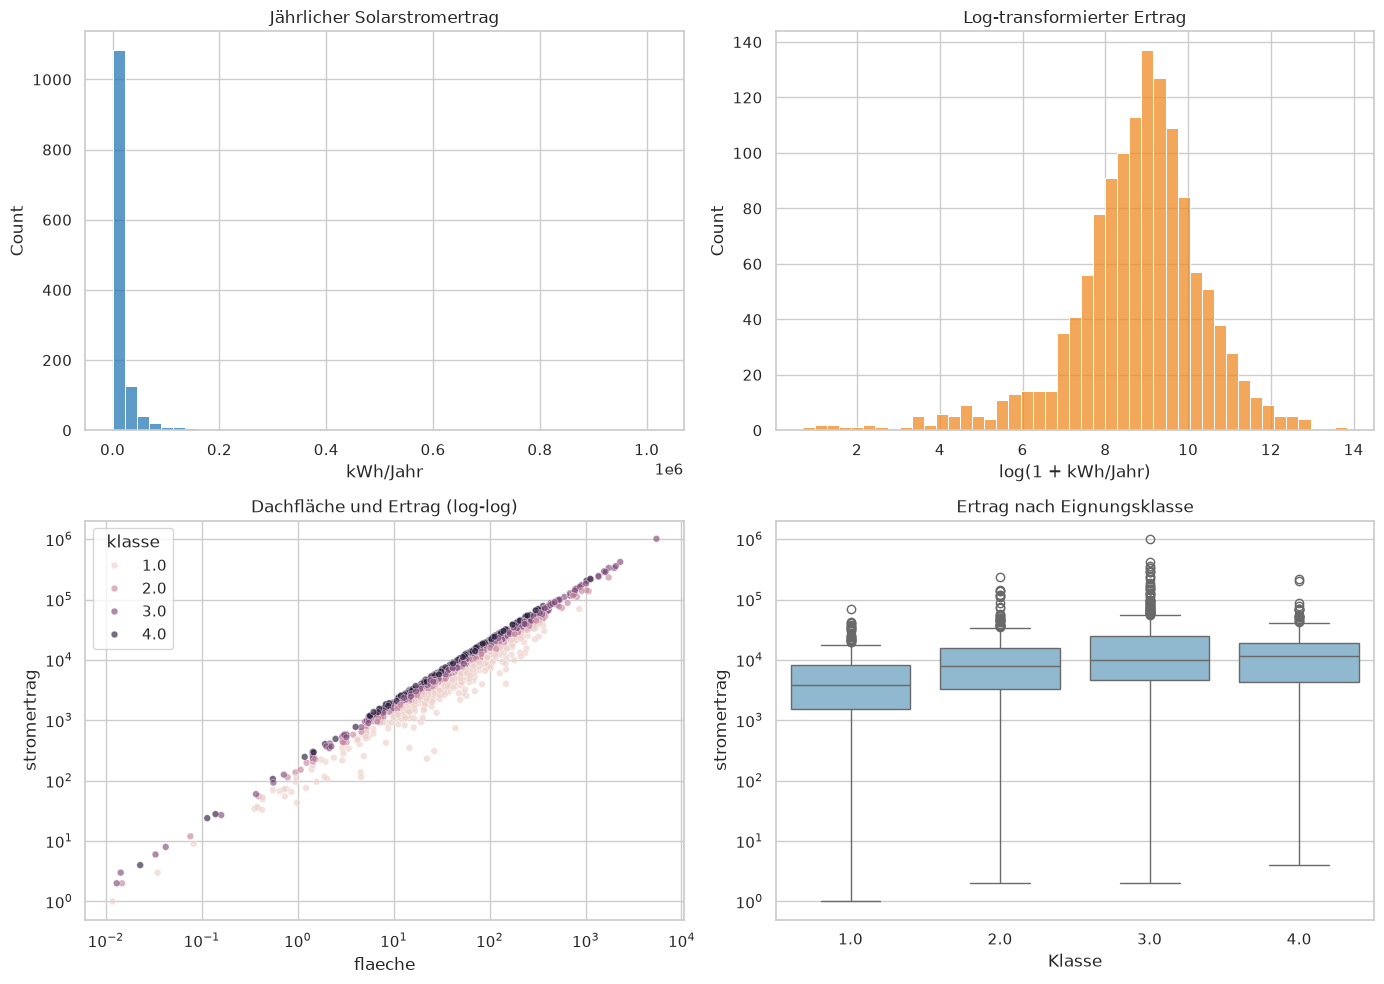

In [15]:
print("Dachflächen je Eignungsklasse:")
display(
    df.groupby("klasse", dropna=False)
    .agg(
        dachflaechen=("featureId", "count"),
        gebaeude=("building_id", "nunique"),
        median_flaeche_m2=("flaeche", "median"),
        median_ertrag_kwh_jahr=("stromertrag", "median"),
        mittelwert_ertrag_kwh_jahr=("stromertrag", "mean"),
    )
    .round(2)
)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sns.histplot(df["stromertrag"], bins=45, ax=axes[0, 0], color="#2878B5")
axes[0, 0].set(title="Jährlicher Solarstromertrag", xlabel="kWh/Jahr")
sns.histplot(np.log1p(df["stromertrag"]), bins=45, ax=axes[0, 1], color="#F08A24")
axes[0, 1].set(title="Log-transformierter Ertrag", xlabel="log(1 + kWh/Jahr)")
sns.scatterplot(
    data=df,
    x="flaeche",
    y="stromertrag",
    hue="klasse",
    alpha=0.65,
    s=24,
    ax=axes[1, 0],
)
axes[1, 0].set(xscale="log", yscale="log", title="Dachfläche und Ertrag (log-log)")
sns.boxplot(data=df, x="klasse", y="stromertrag", ax=axes[1, 1], color="#86BBD8")
axes[1, 1].set(yscale="log", title="Ertrag nach Eignungsklasse", xlabel="Klasse")
fig.tight_layout()
plt.show()

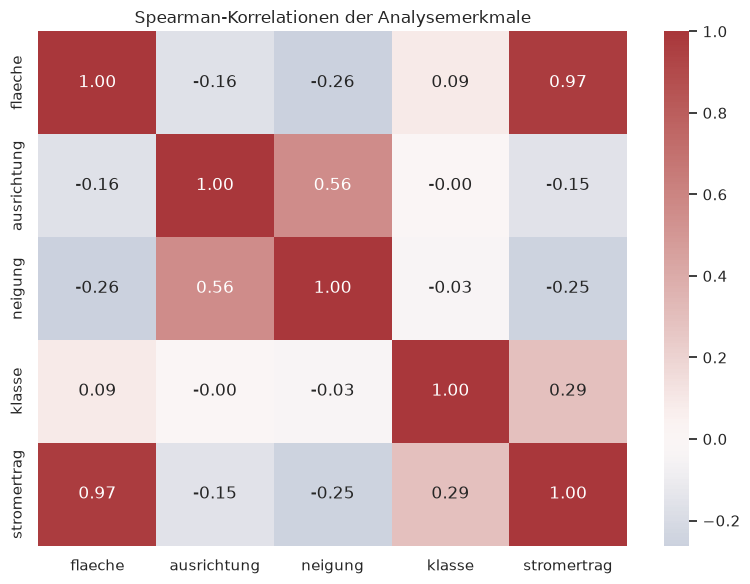

In [16]:
eda_features = ["flaeche", "ausrichtung", "neigung", "klasse", "stromertrag"]
corr_matrix = df[eda_features].corr(method="spearman")
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap="vlag", center=0, fmt=".2f")
plt.title("Spearman-Korrelationen der Analysemerkmale")
plt.tight_layout()
plt.show()

## 5. Räumliche Visualisierung

Die API liefert Dachumrisse in LV95 (EPSG:2056). Für die interaktive
Folium-Karte werden die Koordinaten nach WGS84 (EPSG:4326) transformiert.
Die Kartenfarbe zeigt den geschätzten Ertrag pro Dachfläche, nicht eine
Messung real produzierten Stroms.

In [17]:
def build_geojson_features(data: pd.DataFrame) -> list[dict]:
    """Erstellt Kartenfeatures aus bereinigten Zeilen mit GeoJSON-Geometrie."""
    features = []
    for row in data.itertuples(index=False):
        geometry = json.loads(row.geometry_geojson) if row.geometry_geojson else None
        if geometry is None:
            continue
        features.append(
            {
                "type": "Feature",
                "geometry": geometry,
                "properties": {
                    "featureId": int(row.featureId),
                    "building_id": (
                        int(row.building_id) if pd.notna(row.building_id) else "unbekannt"
                    ),
                    "klasse": int(row.klasse) if pd.notna(row.klasse) else "unbekannt",
                    "flaeche_m2": round(float(row.flaeche), 1),
                    "stromertrag_kwh_jahr": round(float(row.stromertrag), 1),
                },
            }
        )
    return features


geo_features = build_geojson_features(df)
if not geo_features:
    raise ValueError("Keine gültigen Geometrien für die Karte vorhanden.")
all_coords = [
    point
    for feature in geo_features
    for ring in feature["geometry"]["coordinates"]
    for point in ring
]
map_center = [
    float(np.mean([point[1] for point in all_coords])),
    float(np.mean([point[0] for point in all_coords])),
]
yield_min = float(df["stromertrag"].min())
yield_max = float(df["stromertrag"].quantile(0.95))
yield_scale = folium.LinearColormap(
    colors=["#2c7bb6", "#abd9e9", "#ffffbf", "#fdae61", "#d7191c"],
    vmin=yield_min,
    vmax=yield_max,
    caption="BFE-Schätzwert Solarstromertrag (kWh/Jahr; Farbskala bis 95. Perzentil)",
)
roof_map = folium.Map(location=map_center, zoom_start=16, tiles="OpenStreetMap")
folium.GeoJson(
    {"type": "FeatureCollection", "features": geo_features},
    name="BFE-Dachflächen",
    style_function=lambda feature: {
        "fillColor": yield_scale(
            min(float(feature["properties"]["stromertrag_kwh_jahr"]), yield_max)
        ),
        "color": "#343a40",
        "weight": 0.4,
        "fillOpacity": 0.72,
    },
    tooltip=folium.GeoJsonTooltip(
        fields=[
            "building_id",
            "klasse",
            "flaeche_m2",
            "stromertrag_kwh_jahr",
        ],
        aliases=["Gebäude-ID", "Eignungsklasse", "Fläche (m²)", "Ertrag (kWh/Jahr)"],
    ),
).add_to(roof_map)
yield_scale.add_to(roof_map)
folium.LayerControl().add_to(roof_map)
roof_map.save(MAP_HTML)
print(f"Karte gespeichert unter {MAP_HTML}; dargestellte Dachflächen: {len(geo_features):,}")
roof_map

Karte gespeichert unter /workspaces/project_template_arm/Project/sonnendach_winterthur_karte.html; dargestellte Dachflächen: 1,312


## 6. Statistischer Zusammenhang mit p-Wert

Der Spearman-Test prüft einen monotonen Zusammenhang zwischen Dachfläche
und geschätztem Solarstromertrag. Der p-Wert quantifiziert die Evidenz gegen
die Nullhypothese eines Zusammenhangs von null. Bei großer Stichprobe sind
auch kleine Effekte oft statistisch signifikant; deshalb werden rho und
p-Wert gemeinsam berichtet. Eine Korrelation ist keine Kausalitätsaussage.

In [18]:
rho, p_value = spearmanr(df["flaeche"], df["stromertrag"])
print(f"Spearman rho (Dachfläche, Ertrag): {rho:.3f}")
print(f"p-Wert: {'< 0.001' if p_value < 0.001 else f'{p_value:.3g}'}")
if p_value < 0.05:
    print(
        "Interpretation: Der monotone Zusammenhang ist auf dem 5%-Niveau "
        "statistisch signifikant; die Stärke des Zusammenhangs ist rho."
    )
else:
    print("Interpretation: Auf dem 5%-Niveau ist kein statistisch signifikanter Zusammenhang belegt.")

Spearman rho (Dachfläche, Ertrag): 0.966
p-Wert: < 0.001
Interpretation: Der monotone Zusammenhang ist auf dem 5%-Niveau statistisch signifikant; die Stärke des Zusammenhangs ist rho.


## 7. Vorhersagemodelle und gebäudeweiser Test

Verglichen werden multiple lineare Regression und Random Forest Regression.
Der Zielwert wird intern mit `log1p` transformiert, um die starke
Rechtsschiefe abzumildern; Kennzahlen werden nach Rücktransformation in
kWh/Jahr auf der ursprünglichen Skala berechnet.

Als Prädiktoren dienen ausschließlich Fläche, Neigung und die zirkuläre
Kodierung der Ausrichtung. `gstrahlung`, Eignungsklasse, Finanz-/Ertrags-
Teilsummen und Gebäude-IDs werden ausgeschlossen, weil sie das Ergebnis
bereits enthalten, daraus abgeleitet sind oder keine verallgemeinerbaren
Dachmerkmale darstellen.

Der gruppierte 80/20-Split hält alle Dachflächen desselben Gebäudes in
genau einer Teilmenge. R² beschreibt erklärte Varianz, RMSE gewichtet große
Fehler stärker und MAE ist der mittlere absolute Fehler. Die Metriken sind
keine Aussage über reale Anlagenproduktion.

In [19]:
FEATURES = ["log_flaeche", "ausrichtung_sin", "ausrichtung_cos", "neigung"]
TARGET = "stromertrag"
X = df[FEATURES]
y = df[TARGET]
groups = df["building_group"]

splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
train_idx, test_idx = next(splitter.split(X, y, groups=groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
train_groups = set(groups.iloc[train_idx])
test_groups = set(groups.iloc[test_idx])
assert train_groups.isdisjoint(test_groups), "Gebäude-Leakage im Train/Test-Split."
print(
    f"Training: {len(train_idx):,} Dächer / {len(train_groups):,} Gebäude; "
    f"Test: {len(test_idx):,} Dächer / {len(test_groups):,} Gebäude."
)
print(f"Gebäude-Überlappung: {len(train_groups & test_groups)}")

models = {
    "Multiple lineare Regression": TransformedTargetRegressor(
        regressor=make_pipeline(StandardScaler(), LinearRegression()),
        func=np.log1p,
        inverse_func=np.expm1,
    ),
    "Random Forest": TransformedTargetRegressor(
        regressor=RandomForestRegressor(
            n_estimators=400,
            min_samples_leaf=3,
            random_state=SEED,
            n_jobs=-1,
        ),
        func=np.log1p,
        inverse_func=np.expm1,
    ),
}

predictions: dict[str, np.ndarray] = {}
metric_rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    prediction = np.maximum(model.predict(X_test), 0)
    predictions[name] = prediction
    metric_rows.append(
        {
            "Modell": name,
            "R²": r2_score(y_test, prediction),
            "RMSE_kWh_Jahr": np.sqrt(mean_squared_error(y_test, prediction)),
            "MAE_kWh_Jahr": mean_absolute_error(y_test, prediction),
        }
    )

baseline_prediction = np.full(len(y_test), y_train.median())
metric_rows.append(
    {
        "Modell": "Baseline (Trainingsmedian)",
        "R²": r2_score(y_test, baseline_prediction),
        "RMSE_kWh_Jahr": np.sqrt(mean_squared_error(y_test, baseline_prediction)),
        "MAE_kWh_Jahr": mean_absolute_error(y_test, baseline_prediction),
    }
)
metrics = pd.DataFrame(metric_rows).set_index("Modell").sort_values("RMSE_kWh_Jahr")
display(metrics.round(3))

Training: 1,030 Dächer / 246 Gebäude; Test: 282 Dächer / 62 Gebäude.
Gebäude-Überlappung: 0


,R²,RMSE_kWh_Jahr,MAE_kWh_Jahr
Modell,,,
Random Forest,0.970,5024.508,2090.077
Multiple lineare Regression,0.952,6366.945,2601.934
Baseline (Trainingsmedian),-0.046,29826.622,11371.344


## 8. Ergebnisinterpretation und Modell-Diagnostik

Die Rangfolge wird anhand des Test-RMSE bestimmt. R² nahe 1 bedeutet, dass
das Modell einen großen Anteil der Teststreuung erklärt; R² nahe 0 ist
ungefähr nicht besser als eine Vorhersage des Testmittelwerts, negatives R²
ist schlechter. Ein niedrigerer RMSE/MAE ist besser. Die tatsächlichen
Zahlen unten werden bei jeder Notebook-Ausführung aus dem API-Datensatz neu
berechnet und sind nicht vorab festgeschrieben.

Bestes Modell nach Test-RMSE: Random Forest
Test-R² = 0.970, RMSE = 5024.5 kWh/Jahr, MAE = 2090.1 kWh/Jahr.
Interpretation: Das beste Modell erklärt 97.0% der Streuung des BFE-Zielwerts im Gebäude-holdout-Test.
Das beste Modell senkt den RMSE gegenüber der Median-Baseline um 83.2% auf zuvor ungesehene Gebäude.
Die Ergebnisse gelten für die BFE-Potenzialschätzungen im ausgewählten Winterthurer Gebiet. Sie zeigen keine kausale Wirkung und sind nicht ohne neue Validierung auf andere Regionen oder reale Anlagen übertragbar.


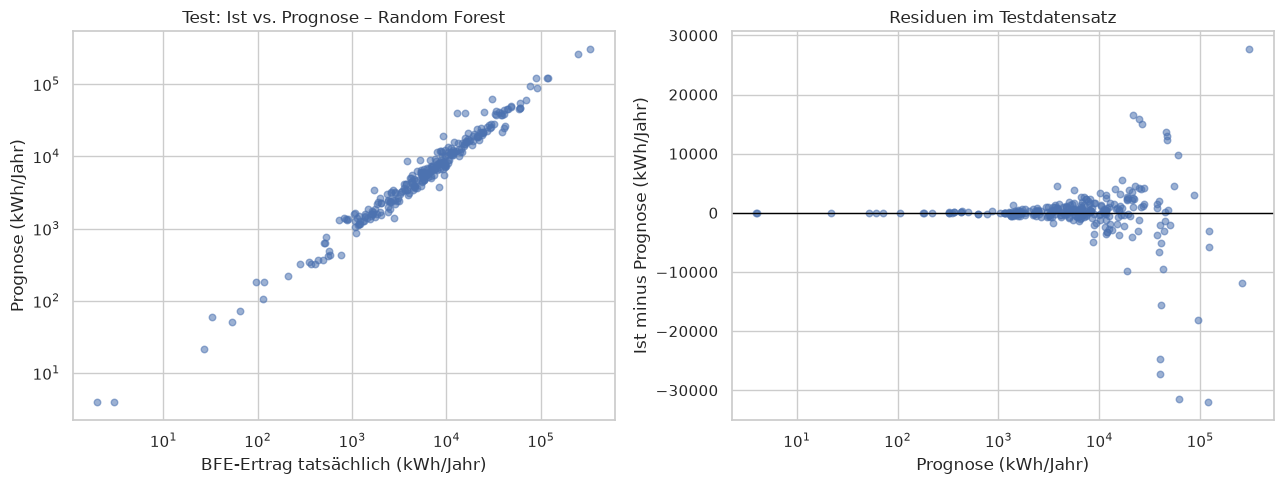

Random-Forest-Merkmalswichtigkeit (deskriptiv, keine Kausalwirkung):


,Wichtigkeit
log_flaeche,0.982
ausrichtung_cos,0.012
neigung,0.004
ausrichtung_sin,0.002


In [20]:
best_model_name = metrics.index[0]
best_metrics = metrics.loc[best_model_name]
baseline_metrics = metrics.loc["Baseline (Trainingsmedian)"]
print(f"Bestes Modell nach Test-RMSE: {best_model_name}")
print(
    f"Test-R² = {best_metrics['R²']:.3f}, "
    f"RMSE = {best_metrics['RMSE_kWh_Jahr']:.1f} kWh/Jahr, "
    f"MAE = {best_metrics['MAE_kWh_Jahr']:.1f} kWh/Jahr."
)
if best_metrics["R²"] >= 0:
    print(
        f"Interpretation: Das beste Modell erklärt {best_metrics['R²']:.1%} "
        "der Streuung des BFE-Zielwerts im Gebäude-holdout-Test."
    )
else:
    print(
        "Interpretation: Das beste Modell erklärt im Test weniger Varianz "
        "als eine konstante Vorhersage des Testmittelwerts (R² < 0)."
    )
if best_model_name != "Baseline (Trainingsmedian)" and (
    best_metrics["RMSE_kWh_Jahr"] < baseline_metrics["RMSE_kWh_Jahr"]
):
    relative_rmse_improvement = (
        1 - best_metrics["RMSE_kWh_Jahr"] / baseline_metrics["RMSE_kWh_Jahr"]
    ) * 100
    print(
        f"Das beste Modell senkt den RMSE gegenüber der Median-Baseline um "
        f"{relative_rmse_improvement:.1f}% auf zuvor ungesehene Gebäude."
    )
else:
    print(
        "Keines der Regressionsmodelle verbessert den Test-RMSE gegenüber "
        "der Median-Baseline. Die verfügbaren Dachmerkmale reichen für "
        "verlässliche Ertragsprognosen in diesem Gebiet nicht aus."
    )
print(
    "Die Ergebnisse gelten für die BFE-Potenzialschätzungen im ausgewählten "
    "Winterthurer Gebiet. Sie zeigen keine kausale Wirkung und sind nicht "
    "ohne neue Validierung auf andere Regionen oder reale Anlagen übertragbar."
)

best_prediction = predictions.get(best_model_name)
if best_prediction is not None:
    residuals = y_test.to_numpy() - best_prediction
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    axes[0].scatter(y_test, best_prediction, alpha=0.55, s=22)
    axes[0].set_xscale("log")
    axes[0].set_yscale("log")
    axes[0].set(
        title=f"Test: Ist vs. Prognose – {best_model_name}",
        xlabel="BFE-Ertrag tatsächlich (kWh/Jahr)",
        ylabel="Prognose (kWh/Jahr)",
    )
    axes[1].scatter(best_prediction, residuals, alpha=0.55, s=22)
    axes[1].axhline(0, color="black", linewidth=1)
    axes[1].set_xscale("log")
    axes[1].set(
        title="Residuen im Testdatensatz",
        xlabel="Prognose (kWh/Jahr)",
        ylabel="Ist minus Prognose (kWh/Jahr)",
    )
    fig.tight_layout()
    plt.show()

rf_model = models["Random Forest"].regressor_
rf_importance = pd.Series(
    rf_model.feature_importances_, index=FEATURES, name="Wichtigkeit"
).sort_values(ascending=False)
print("Random-Forest-Merkmalswichtigkeit (deskriptiv, keine Kausalwirkung):")
display(rf_importance.to_frame().round(3))

## 9. Fazit, Grenzen und Weitergabe

**Fazit:** Die Tabellen und Grafiken quantifizieren Verteilung,
Gebäudecluster, räumliches Muster, statistischen Flächen-Ertrags-
Zusammenhang und die Vorhersagegüte beider Regressionsmodelle. Die
Schlussfolgerungen sind aus den oben ausgegebenen, bei der Ausführung
berechneten Kennzahlen abzuleiten.

**Grenzen:** (1) kleines, räumlich begrenztes Gebiet; (2) BFE-Potenzial ist
eine Modellschätzung, kein real gemessener Ertrag; (3) nur 1.312 gültige
Dachflächen; (4) mehrere Dächer je Gebäude und bewusst gebäudeweiser Split;
(5) APIs und Modellversionen können sich ändern; (6) p-Werte belegen keine
Kausalität; (7) hohe Ausreißer bleiben erhalten und beeinflussen RMSE.

**Moodle-Abgabe:** Vor der Abgabe dieses Notebook von oben nach unten
ausführen und mit den Outputs speichern. Dazu `solar_test_..._raw.csv`,
`solar_test_..._clean.csv`, die SQLite-Datei und optional die HTML-Karte
hochladen. Persönliche Moodle-Anmeldung/Upload kann nicht automatisiert
werden. Quellen: geo.admin.ch REST API, Layer
`ch.bfe.solarenergie-eignung-daecher`, Koordinatenbereich/BBOX oben;
Abrufdatum beim Ausführen: aktuelles Datum.

**Video-Präsentation:** Die Bewertung verlangt eine Aufnahme mit
`Gruppengröße × 5 Minuten`. Vor der Aufnahme aktuelle Kennzahlen aus diesem
Notebook übernehmen. Vorschlag: Frage & Datensatz (15%), API und
Datenbereinigung (20%), EDA & Karte (20%), Methode und gebäudeweiser Split
(20%), Modellvergleich und Interpretation (20%), Grenzen/Fazit (5%).
Jedes Gruppenmitglied sollte einen Abschnitt frei erläutern; Notebook,
Folien und sichtbare Visualisierungen als Hilfsmittel verwenden.

**Kreative Vertiefung:** [Interaktives Dozenten-Quiz](./quiz_dozent.html) (offline im Browser spielbar).